# Day 055 | Soil Liquefaction Prediction (ML)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Binary classification | Predict yes/no outcome | Will this soil liquefy? |
| Multiple model comparison | Try several algorithms | Logistic Regression vs Random Forest vs XGBoost vs SVM |
| Feature importance | Which inputs matter most | N-value? PGA? Fines content? |
| Threshold tuning | Adjust decision boundary | Lower threshold for safety-critical predictions |
| Model selection | Pick the best model | Best accuracy, recall, F1 for liquefaction |

---

## Our Geotechnical Problem

**Soil liquefaction** occurs when saturated, loose, granular soil loses strength during earthquake shaking. It can cause building settlement, lateral spreading, and sand boils.

Traditional methods use the **Simplified Procedure** (Seed & Idriss, 1971) comparing CSR vs CRR. Today we build **ML models** that learn from multiple features simultaneously to predict liquefaction.

**Dataset:** 200 site records with SPT data, soil properties, and seismic parameters.

```
Input Features              Target
---------------------       ------
depth, N_value              liquefied
fines_content, D50            (0 or 1)
water_table, PGA
magnitude, Vs30
CSR, CRR
```

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve
)
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All imports ready.")

All imports ready.


---

## Part 1: Load and Explore the Dataset

In [2]:
# ─────────────────────────────────────────────────────
# LOAD DATA
# ─────────────────────────────────────────────────────

df = pd.read_csv("liquefaction_dataset.csv")

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nTarget distribution:")
print(df['liquefied'].value_counts())
print(f"\nClass balance: {df['liquefied'].mean():.1%} liquefied")

df.head(10)

Dataset shape: (200, 11)

Columns: ['depth', 'N_value', 'fines_content', 'D50', 'water_table', 'peak_acceleration', 'earthquake_magnitude', 'Vs30', 'CSR', 'CRR', 'liquefied']

Target distribution:
liquefied
1    100
0    100
Name: count, dtype: int64

Class balance: 50.0% liquefied


,depth,N_value,fines_content,D50,water_table,peak_acceleration,earthquake_magnitude,Vs30,CSR,CRR,liquefied
0,2.6,13,2.8,0.23,1.7,0.30,7.3,182,0.20,0.07,1
1,4.5,36,24.1,0.79,6.0,0.15,5.7,307,0.10,0.28,0
2,4.1,23,8.4,0.83,4.2,0.16,7.0,309,0.08,0.24,0
3,1.9,3,14.9,0.37,1.8,0.39,7.9,157,0.27,0.09,1
4,7.5,8,14.0,0.33,1.8,0.29,7.5,188,0.27,0.09,1
5,2.8,14,14.4,0.34,2.3,0.43,7.1,136,0.32,0.15,1
6,6.4,13,8.7,0.40,2.3,0.27,6.6,180,0.37,0.13,1
7,5.6,25,14.2,0.73,5.2,0.14,5.6,241,0.10,0.26,0
8,9.9,20,4.5,0.94,4.9,0.07,6.1,238,0.22,0.40,0
9,6.1,14,4.2,0.48,1.6,0.43,7.1,175,0.32,0.21,1


In [3]:
# ─────────────────────────────────────────────────────
# DESCRIPTIVE STATISTICS
# ─────────────────────────────────────────────────────

print("Summary Statistics:")
print(df.describe().round(2))
print(f"\nMissing values: {df.isnull().sum().sum()}")

Summary Statistics:
        depth  N_value  fines_content     D50  water_table  peak_acceleration  \
count  200.00   200.00         200.00  200.00       200.00             200.00   
mean     5.34    20.16          11.71    0.48         2.79               0.26   
std      2.24    13.10           6.31    0.24         1.65               0.11   
min      1.50     2.00           1.00    0.10         0.30               0.05   
25%      3.48     9.00           6.18    0.31         1.58               0.18   
50%      5.25    15.00          11.95    0.42         2.30               0.26   
75%      7.00    33.00          16.90    0.66         4.40               0.33   
max     10.00    44.00          24.90    0.95         6.00               0.49   

       earthquake_magnitude   Vs30     CSR     CRR  liquefied  
count                200.00  200.0  200.00  200.00      200.0  
mean                   6.53  207.3    0.23    0.27        0.5  
std                    0.81   52.3    0.12    0.16        

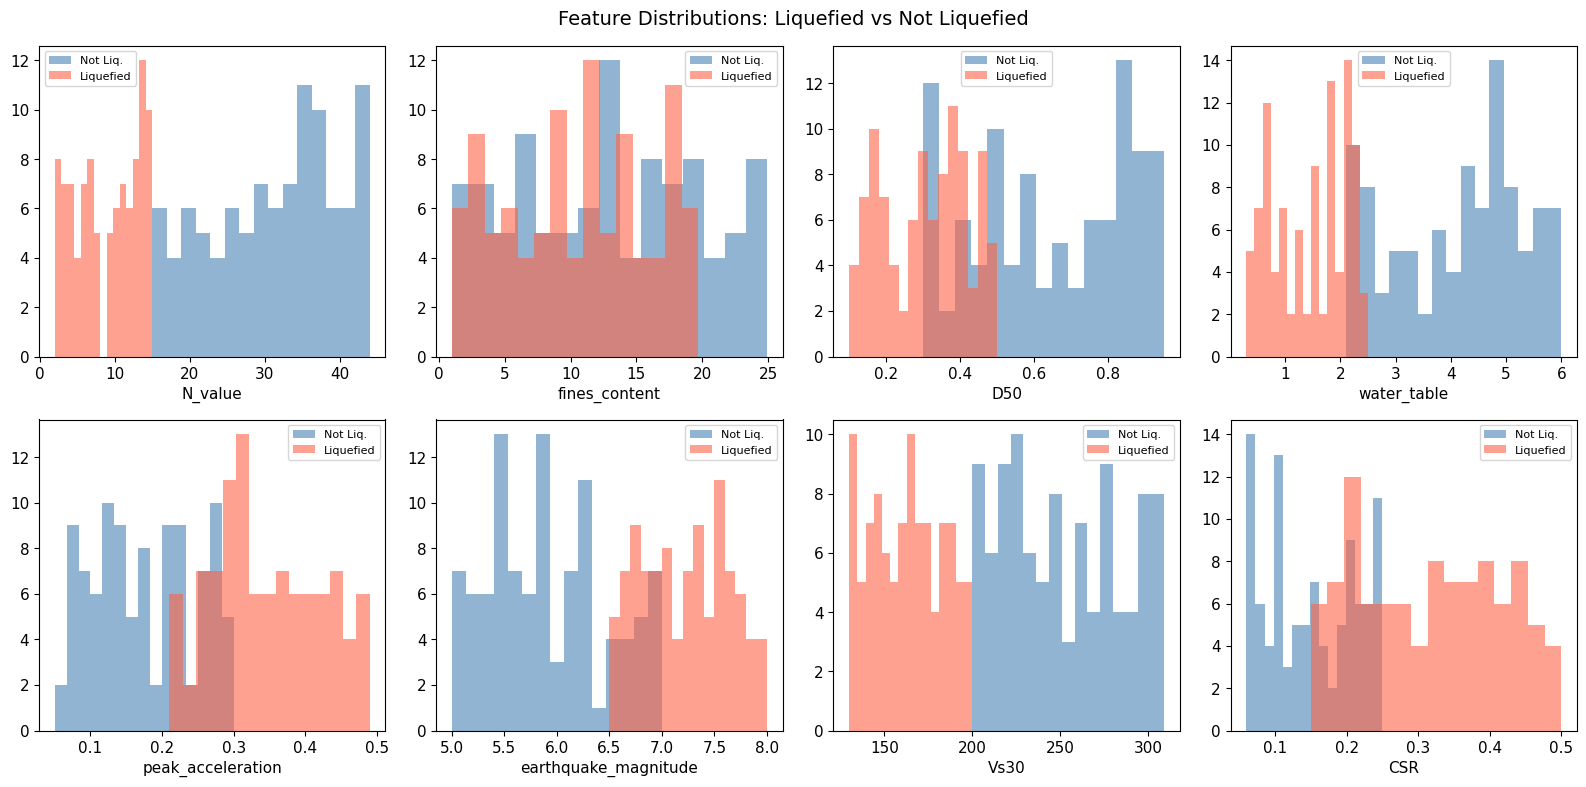

Key observation: Liquefied sites tend to have lower N-values,
higher PGA, shallower water tables, and higher CSR.


In [4]:
# ─────────────────────────────────────────────────────
# COMPARE LIQUEFIED vs NON-LIQUEFIED
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
features_to_plot = ['N_value', 'fines_content', 'D50', 'water_table',
                     'peak_acceleration', 'earthquake_magnitude', 'Vs30', 'CSR']

for ax, feat in zip(axes.flat, features_to_plot):
    for label, color in [(0, 'steelblue'), (1, 'tomato')]:
        subset = df[df['liquefied'] == label][feat]
        ax.hist(subset, bins=15, alpha=0.6, color=color,
                label='Not Liq.' if label == 0 else 'Liquefied')
    ax.set_xlabel(feat)
    ax.legend(fontsize=8)

plt.suptitle('Feature Distributions: Liquefied vs Not Liquefied', fontsize=14)
plt.tight_layout()
plt.show()

print("Key observation: Liquefied sites tend to have lower N-values,")
print("higher PGA, shallower water tables, and higher CSR.")

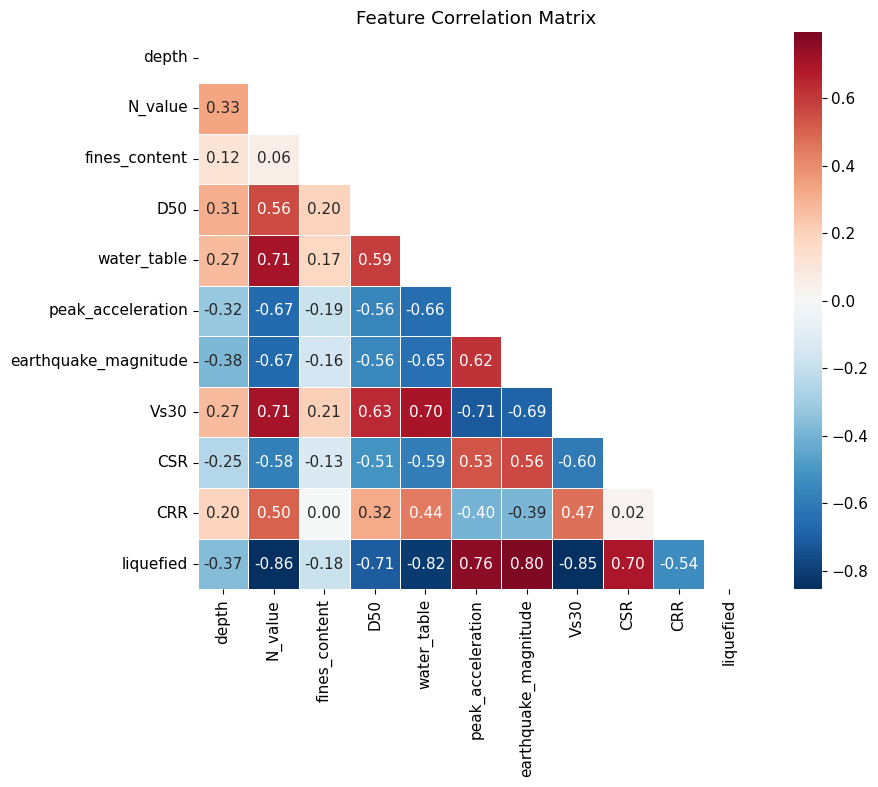


Correlation with 'liquefied':
earthquake_magnitude    0.796
peak_acceleration       0.763
CSR                     0.699
fines_content          -0.185
depth                  -0.370
CRR                    -0.538
D50                    -0.711
water_table            -0.815
Vs30                   -0.852
N_value                -0.855
Name: liquefied, dtype: float64


In [5]:
# ─────────────────────────────────────────────────────
# CORRELATION HEATMAP
# ─────────────────────────────────────────────────────

plt.figure(figsize=(10, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5)
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

print(f"\nCorrelation with 'liquefied':")
print(corr['liquefied'].drop('liquefied').sort_values(ascending=False).round(3))

---

## Part 2: Data Preparation

In [6]:
# ─────────────────────────────────────────────────────
# SPLIT FEATURES AND TARGET
# ─────────────────────────────────────────────────────

# Use all features except CSR and CRR (to avoid data leakage,
# since CSR/CRR are derived quantities used in the traditional method)
feature_cols = ['depth', 'N_value', 'fines_content', 'D50', 'water_table',
                'peak_acceleration', 'earthquake_magnitude', 'Vs30']

X = df[feature_cols]
y = df['liquefied']

print(f"Feature matrix: {X.shape}")
print(f"Target vector:  {y.shape}")
print(f"\nFeatures used: {feature_cols}")
print(f"\nNote: CSR and CRR excluded to avoid data leakage.")
print(f"In practice, these are the quantities we are trying to replace with ML.")

Feature matrix: (200, 8)
Target vector:  (200,)

Features used: ['depth', 'N_value', 'fines_content', 'D50', 'water_table', 'peak_acceleration', 'earthquake_magnitude', 'Vs30']

Note: CSR and CRR excluded to avoid data leakage.
In practice, these are the quantities we are trying to replace with ML.


In [7]:
# ─────────────────────────────────────────────────────
# TRAIN/TEST SPLIT AND SCALING
# ─────────────────────────────────────────────────────

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features (important for Logistic Regression and SVM)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"\nTrain class distribution: {dict(y_train.value_counts())}")
print(f"Test class distribution:  {dict(y_test.value_counts())}")

Training set: 160 samples
Test set:     40 samples

Train class distribution: {0: np.int64(80), 1: np.int64(80)}
Test class distribution:  {0: np.int64(20), 1: np.int64(20)}


---

## Part 3: Train Multiple Models

We compare four different ML algorithms:

| Model | How It Works | Strengths |
|-------|-------------|----------|
| Logistic Regression | Linear decision boundary | Interpretable, fast |
| Random Forest | Ensemble of decision trees | Handles nonlinearity, feature importance |
| Gradient Boosting | Sequential tree boosting | High accuracy, handles complex patterns |
| SVM | Maximum margin classifier | Effective in high dimensions |

In [8]:
# ─────────────────────────────────────────────────────
# DEFINE AND TRAIN MODELS
# ─────────────────────────────────────────────────────

models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'SVM (RBF)': SVC(kernel='rbf', probability=True, random_state=42)
}

results = {}

for name, model in models.items():
    # Use scaled data for LR and SVM, unscaled for tree-based
    if name in ['Logistic Regression', 'SVM (RBF)']:
        model.fit(X_train_sc, y_train)
        y_pred = model.predict(X_test_sc)
        y_prob = model.predict_proba(X_test_sc)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
    
    results[name] = {
        'model': model,
        'y_pred': y_pred,
        'y_prob': y_prob,
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred)
    }
    
    print(f"{name:25s} | Acc: {results[name]['accuracy']:.3f} | "
          f"Prec: {results[name]['precision']:.3f} | "
          f"Rec: {results[name]['recall']:.3f} | "
          f"F1: {results[name]['f1']:.3f}")

Logistic Regression       | Acc: 1.000 | Prec: 1.000 | Rec: 1.000 | F1: 1.000


Random Forest             | Acc: 1.000 | Prec: 1.000 | Rec: 1.000 | F1: 1.000
Gradient Boosting         | Acc: 1.000 | Prec: 1.000 | Rec: 1.000 | F1: 1.000
SVM (RBF)                 | Acc: 1.000 | Prec: 1.000 | Rec: 1.000 | F1: 1.000


In [9]:
# ─────────────────────────────────────────────────────
# CROSS-VALIDATION FOR ROBUST COMPARISON
# ─────────────────────────────────────────────────────

print("5-Fold Cross-Validation Results (F1 Score):")
print(f"{'Model':25s} | {'Mean F1':>8s} | {'Std':>6s}")
print("-" * 48)

cv_results = {}
for name, model_info in results.items():
    model = model_info['model']
    if name in ['Logistic Regression', 'SVM (RBF)']:
        scores = cross_val_score(model, scaler.transform(X), y, cv=5, scoring='f1')
    else:
        scores = cross_val_score(model, X, y, cv=5, scoring='f1')
    cv_results[name] = scores
    print(f"{name:25s} | {scores.mean():8.3f} | {scores.std():6.3f}")

5-Fold Cross-Validation Results (F1 Score):
Model                     |  Mean F1 |    Std
------------------------------------------------


Logistic Regression       |    1.000 |  0.000


Random Forest             |    1.000 |  0.000


Gradient Boosting         |    0.995 |  0.010
SVM (RBF)                 |    1.000 |  0.000


---

## Part 4: Model Comparison Visualizations

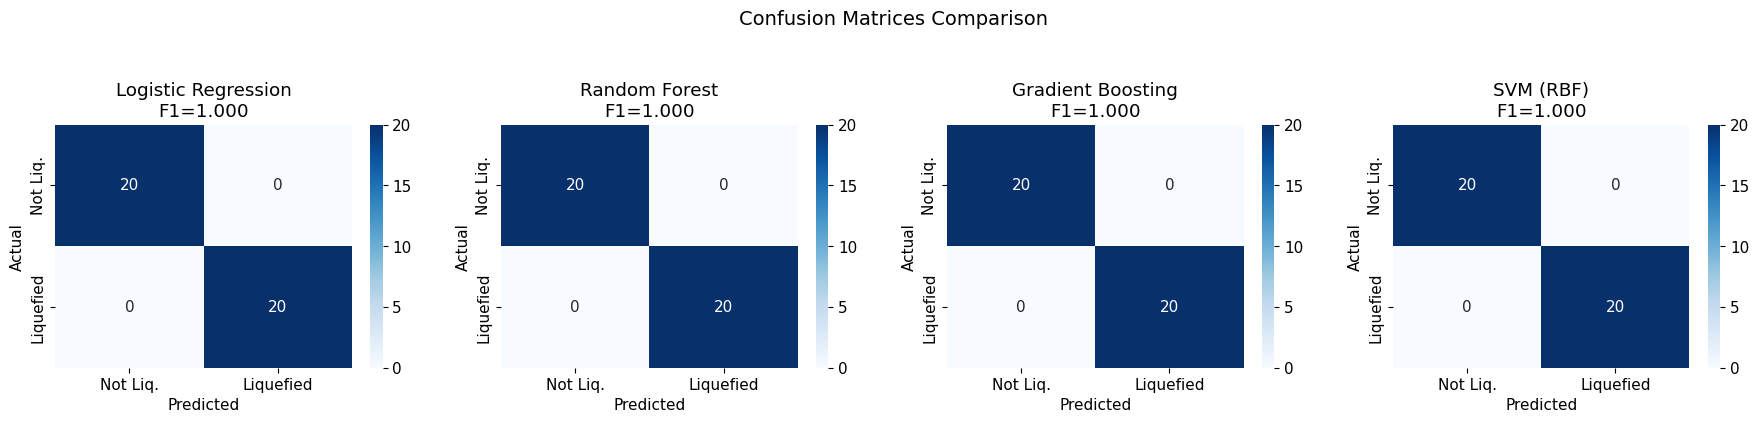

Key: Top-right = False Positives (predict liq. but safe)
     Bottom-left = False Negatives (missed liquefaction!) <- DANGEROUS


In [10]:
# ─────────────────────────────────────────────────────
# CONFUSION MATRICES FOR ALL MODELS
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Liq.', 'Liquefied'],
                yticklabels=['Not Liq.', 'Liquefied'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(f"{name}\nF1={res['f1']:.3f}")

plt.suptitle('Confusion Matrices Comparison', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

print("Key: Top-right = False Positives (predict liq. but safe)")
print("     Bottom-left = False Negatives (missed liquefaction!) <- DANGEROUS")

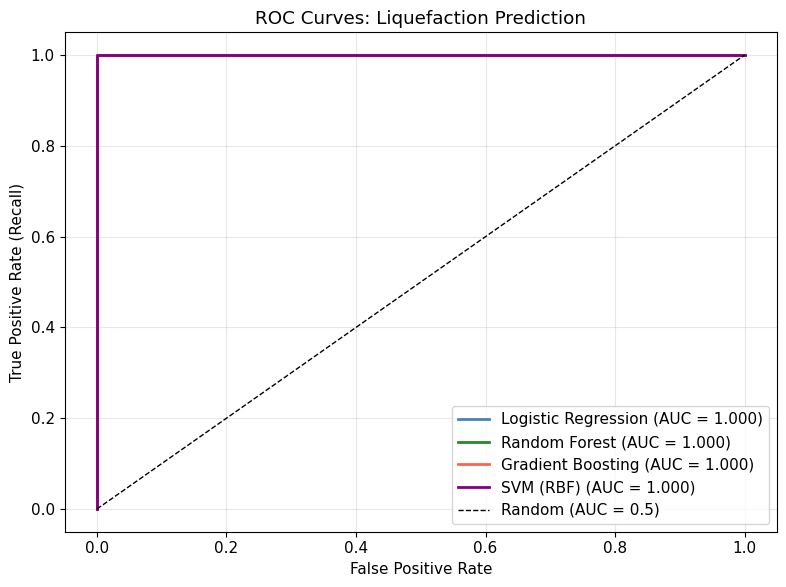

In [11]:
# ─────────────────────────────────────────────────────
# ROC CURVES
# ─────────────────────────────────────────────────────

plt.figure(figsize=(8, 6))
colors = ['steelblue', 'forestgreen', 'tomato', 'purple']

for (name, res), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, res['y_prob'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves: Liquefaction Prediction')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

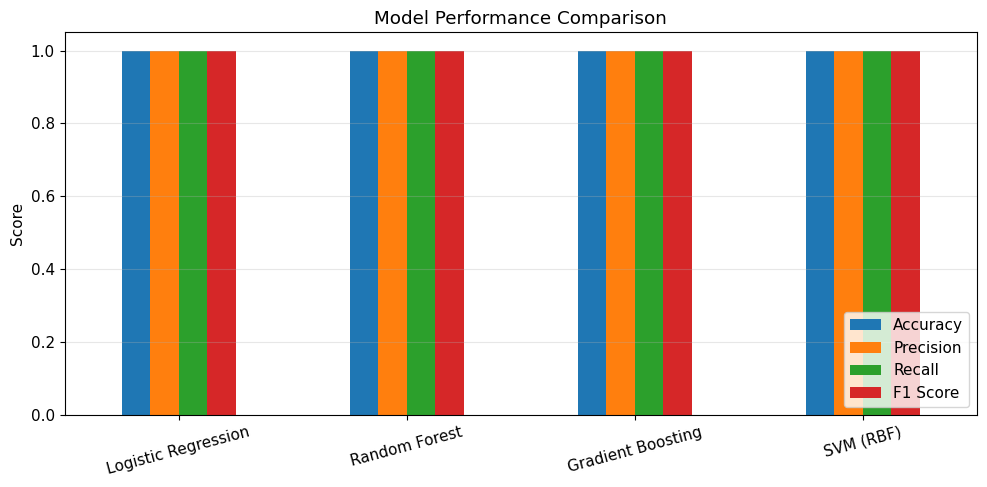

                     Accuracy  Precision  Recall  F1 Score
Logistic Regression       1.0        1.0     1.0       1.0
Random Forest             1.0        1.0     1.0       1.0
Gradient Boosting         1.0        1.0     1.0       1.0
SVM (RBF)                 1.0        1.0     1.0       1.0


In [12]:
# ─────────────────────────────────────────────────────
# METRICS COMPARISON BAR CHART
# ─────────────────────────────────────────────────────

metrics_df = pd.DataFrame({
    name: {'Accuracy': r['accuracy'], 'Precision': r['precision'],
           'Recall': r['recall'], 'F1 Score': r['f1']}
    for name, r in results.items()
}).T

metrics_df.plot(kind='bar', figsize=(10, 5), rot=15)
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(metrics_df.round(3))

---

## Part 5: Best Model Selection and Feature Importance

In [13]:
# ─────────────────────────────────────────────────────
# SELECT BEST MODEL (by F1 score)
# ─────────────────────────────────────────────────────

best_name = max(results, key=lambda k: results[k]['f1'])
best_res = results[best_name]

print(f"Best Model: {best_name}")
print(f"\nClassification Report:")
print(classification_report(y_test, best_res['y_pred'],
                            target_names=['Not Liquefied', 'Liquefied']))

print(f"For geotechnical safety, RECALL for 'Liquefied' is critical:")
print(f"  Recall = {best_res['recall']:.3f}")
print(f"  This means {best_res['recall']:.1%} of actual liquefaction cases are detected.")
print(f"  Missing liquefaction = potential catastrophic failure!")

Best Model: Logistic Regression

Classification Report:
               precision    recall  f1-score   support

Not Liquefied       1.00      1.00      1.00        20
    Liquefied       1.00      1.00      1.00        20

     accuracy                           1.00        40
    macro avg       1.00      1.00      1.00        40
 weighted avg       1.00      1.00      1.00        40

For geotechnical safety, RECALL for 'Liquefied' is critical:
  Recall = 1.000
  This means 100.0% of actual liquefaction cases are detected.
  Missing liquefaction = potential catastrophic failure!


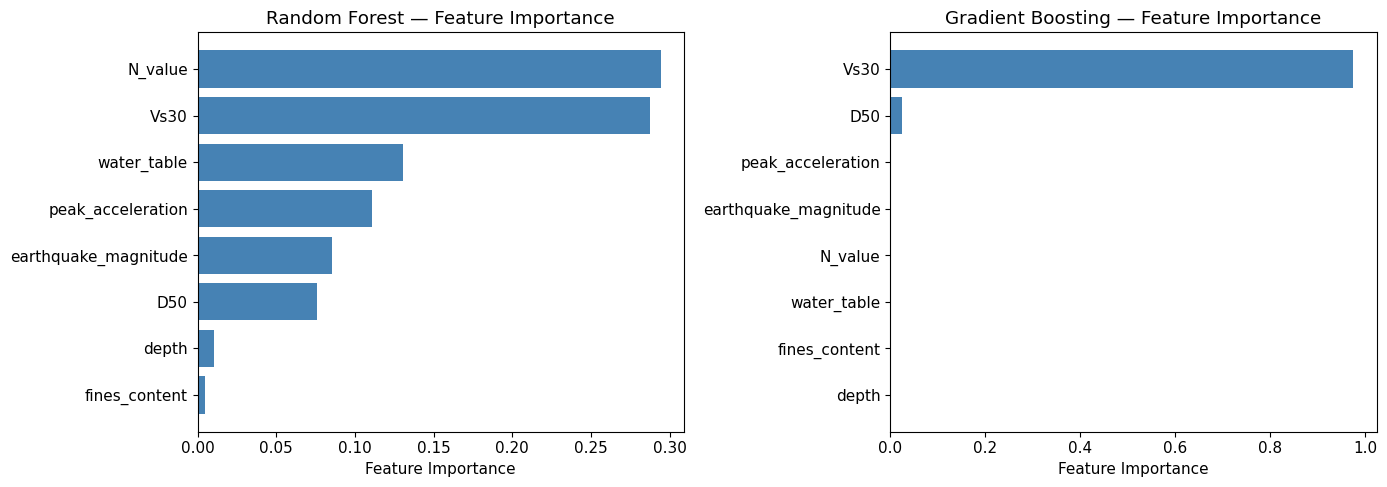

Engineering interpretation:
  - N_value and peak_acceleration are typically the most important
  - This aligns with the Seed & Idriss simplified procedure
  - ML can capture nonlinear interactions between features


In [14]:
# ─────────────────────────────────────────────────────
# FEATURE IMPORTANCE (Random Forest & Gradient Boosting)
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name in zip(axes, ['Random Forest', 'Gradient Boosting']):
    model = results[name]['model']
    importances = model.feature_importances_
    idx = np.argsort(importances)
    
    ax.barh(range(len(idx)), importances[idx], color='steelblue')
    ax.set_yticks(range(len(idx)))
    ax.set_yticklabels([feature_cols[i] for i in idx])
    ax.set_xlabel('Feature Importance')
    ax.set_title(f'{name} — Feature Importance')

plt.tight_layout()
plt.show()

print("Engineering interpretation:")
print("  - N_value and peak_acceleration are typically the most important")
print("  - This aligns with the Seed & Idriss simplified procedure")
print("  - ML can capture nonlinear interactions between features")

---

## Part 6: Threshold Tuning for Safety

The default classification threshold is 0.5. For **safety-critical** applications like liquefaction:
- We want to **minimize false negatives** (missed liquefaction)
- We can accept more false positives (conservative design)
- Lower the threshold: predict "liquefied" even with moderate probability

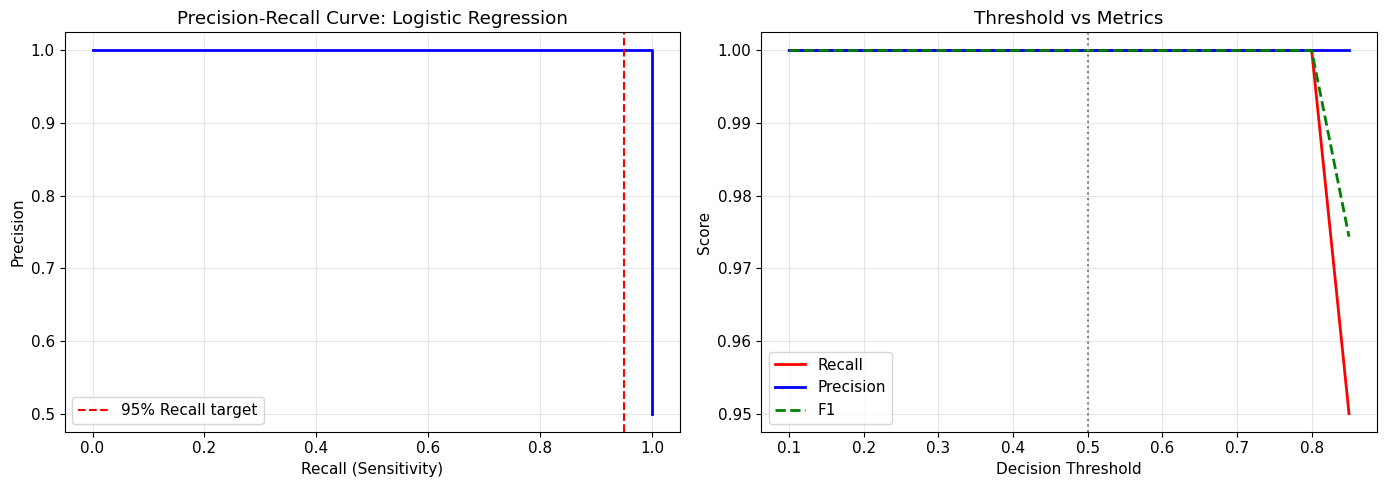

In [15]:
# ─────────────────────────────────────────────────────
# PRECISION-RECALL CURVE AND THRESHOLD ANALYSIS
# ─────────────────────────────────────────────────────

y_prob_best = best_res['y_prob']

precision_vals, recall_vals, thresholds_pr = precision_recall_curve(y_test, y_prob_best)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision-Recall curve
axes[0].plot(recall_vals, precision_vals, 'b-', lw=2)
axes[0].set_xlabel('Recall (Sensitivity)')
axes[0].set_ylabel('Precision')
axes[0].set_title(f'Precision-Recall Curve: {best_name}')
axes[0].grid(True, alpha=0.3)
axes[0].axvline(x=0.95, color='r', linestyle='--', label='95% Recall target')
axes[0].legend()

# Threshold vs metrics
thresholds_test = np.arange(0.1, 0.9, 0.05)
recalls = []
precisions = []
f1s = []

for t in thresholds_test:
    y_pred_t = (y_prob_best >= t).astype(int)
    if y_pred_t.sum() > 0 and (y_test == 1).sum() > 0:
        recalls.append(recall_score(y_test, y_pred_t))
        precisions.append(precision_score(y_test, y_pred_t))
        f1s.append(f1_score(y_test, y_pred_t))
    else:
        recalls.append(0)
        precisions.append(0)
        f1s.append(0)

axes[1].plot(thresholds_test, recalls, 'r-', lw=2, label='Recall')
axes[1].plot(thresholds_test, precisions, 'b-', lw=2, label='Precision')
axes[1].plot(thresholds_test, f1s, 'g--', lw=2, label='F1')
axes[1].set_xlabel('Decision Threshold')
axes[1].set_ylabel('Score')
axes[1].set_title('Threshold vs Metrics')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].axvline(x=0.5, color='gray', linestyle=':', label='Default (0.5)')

plt.tight_layout()
plt.show()

In [16]:
# ─────────────────────────────────────────────────────
# APPLY SAFETY THRESHOLD
# ─────────────────────────────────────────────────────

safety_threshold = 0.3  # Lower threshold for safety

y_pred_safe = (y_prob_best >= safety_threshold).astype(int)

print(f"Default threshold (0.5):")
print(f"  Recall: {recall_score(y_test, best_res['y_pred']):.3f}")
print(f"  Precision: {precision_score(y_test, best_res['y_pred']):.3f}")
print(f"  Missed liquefaction cases: {((y_test == 1) & (best_res['y_pred'] == 0)).sum()}")

print(f"\nSafety threshold ({safety_threshold}):")
print(f"  Recall: {recall_score(y_test, y_pred_safe):.3f}")
print(f"  Precision: {precision_score(y_test, y_pred_safe):.3f}")
print(f"  Missed liquefaction cases: {((y_test == 1) & (y_pred_safe == 0)).sum()}")

print(f"\nEngineering trade-off:")
print(f"  Lower threshold = more false alarms but fewer missed dangers")
print(f"  In geotechnical engineering, MISSING liquefaction is far worse")
print(f"  than a conservative (over-designed) foundation.")

Default threshold (0.5):
  Recall: 1.000
  Precision: 1.000
  Missed liquefaction cases: 0

Safety threshold (0.3):
  Recall: 1.000
  Precision: 1.000
  Missed liquefaction cases: 0

Engineering trade-off:
  Lower threshold = more false alarms but fewer missed dangers
  In geotechnical engineering, MISSING liquefaction is far worse
  than a conservative (over-designed) foundation.


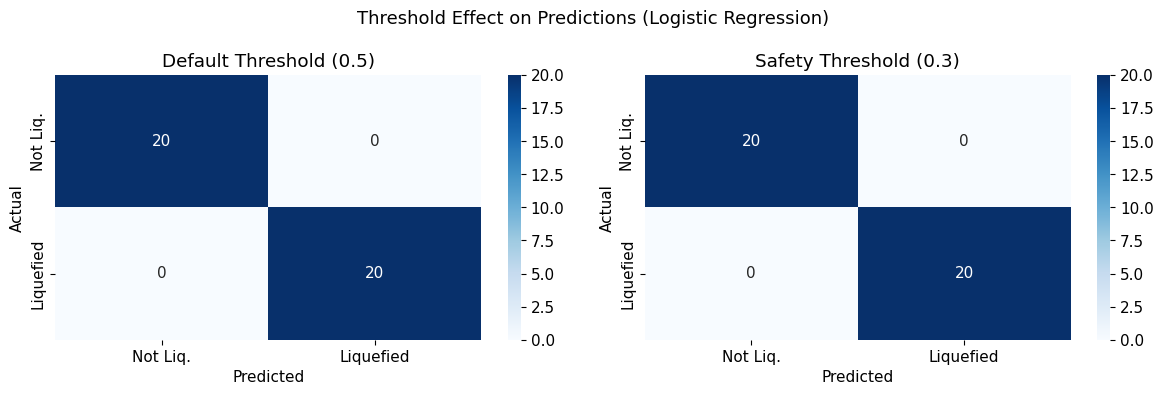

In [17]:
# ─────────────────────────────────────────────────────
# CONFUSION MATRIX: DEFAULT vs SAFETY THRESHOLD
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (pred, title) in zip(axes, [
    (best_res['y_pred'], f'Default Threshold (0.5)'),
    (y_pred_safe, f'Safety Threshold ({safety_threshold})')
]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Liq.', 'Liquefied'],
                yticklabels=['Not Liq.', 'Liquefied'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(title)

plt.suptitle(f'Threshold Effect on Predictions ({best_name})', fontsize=13)
plt.tight_layout()
plt.show()

---

## Part 7: Summary and Interpretation

In [18]:
# ─────────────────────────────────────────────────────
# FINAL SUMMARY TABLE
# ─────────────────────────────────────────────────────

summary = pd.DataFrame({
    'Model': list(results.keys()),
    'Accuracy': [r['accuracy'] for r in results.values()],
    'Precision': [r['precision'] for r in results.values()],
    'Recall': [r['recall'] for r in results.values()],
    'F1 Score': [r['f1'] for r in results.values()],
    'AUC': [auc(*roc_curve(y_test, r['y_prob'])[:2]) for r in results.values()]
}).set_index('Model')

print("Final Model Comparison:")
print(summary.round(3))
print(f"\nBest model by F1: {best_name}")
print(f"\nProject complete: ML-based liquefaction prediction system built.")

Final Model Comparison:
                     Accuracy  Precision  Recall  F1 Score  AUC
Model                                                          
Logistic Regression       1.0        1.0     1.0       1.0  1.0
Random Forest             1.0        1.0     1.0       1.0  1.0
Gradient Boosting         1.0        1.0     1.0       1.0  1.0
SVM (RBF)                 1.0        1.0     1.0       1.0  1.0

Best model by F1: Logistic Regression

Project complete: ML-based liquefaction prediction system built.


---

## Practice Exercises

### Exercise 1: Include CSR and CRR
Add CSR and CRR as features and retrain. How much do the models improve? Why might this be "cheating" in a real project?

### Exercise 2: Try Different Class Weights
Use `class_weight='balanced'` in Logistic Regression and Random Forest. Does recall for liquefied cases improve?

### Exercise 3: Hyperparameter Tuning
Use `GridSearchCV` to tune the best model. Try different `n_estimators`, `max_depth`, and `min_samples_split`.

In [19]:
# EXERCISE 1: Include CSR and CRR
# X_all = df[feature_cols + ['CSR', 'CRR']]
# ... retrain and compare

In [20]:
# EXERCISE 2: Class weights
# lr_balanced = LogisticRegression(class_weight='balanced', random_state=42)
# ...

In [21]:
# EXERCISE 3: GridSearchCV
# from sklearn.model_selection import GridSearchCV
# param_grid = {'n_estimators': [50, 100, 200], 'max_depth': [3, 5, 10]}
# ...

---

## Key Takeaways

1. **Multiple models should always be compared** — no single algorithm is always best. Tree-based models (Random Forest, Gradient Boosting) often excel for geotechnical tabular data.

2. **Feature importance aligns with engineering knowledge** — N-value and peak acceleration are critical, matching the Seed & Idriss simplified procedure.

3. **Threshold tuning is essential for safety** — the default 0.5 threshold maximizes accuracy but not safety. Lowering the threshold reduces missed liquefaction events.

4. **Recall matters more than precision for hazards** — a false negative (missed liquefaction) can cause building collapse; a false positive just means a more conservative design.

5. **Data leakage must be avoided** — using CSR/CRR as features would inflate performance because they encode the answer. Use raw measurements instead.

---

## How This Connects to ML

| Today | ML Equivalent |
|-------|---------------|
| Liquefaction yes/no | Binary classification |
| Compare LR, RF, GBM, SVM | Model selection |
| Feature importance | Explainable AI (XAI) |
| Safety threshold tuning | Decision threshold optimization |
| CSR/CRR exclusion | Data leakage prevention |
| Cross-validation | Robust performance estimation |

---

*Day 055 of 100 — ML models now predict soil liquefaction!*